# Features in datasets

Features are given to datasets, and accessed through the output pattern. In online datasets (raw audio folders),
they are computed on the fly, in data loader workers or on whole batches ; in pre-processed datasets, they are
computed once and stored. This notebook builds a small synthetic dataset and shows :

- features and metadata (from file names) in outputs,
- querying items from metadata,
- batch features in data loaders,
- balancing classes,
- storing features in a pre-processed dataset.

In [1]:
import math, tempfile, collections
from pathlib import Path
import numpy as np
import soundfile as sf
import torch
import matplotlib.pyplot as plt
from acids_dataset import features as F
from acids_dataset.datasets import AudioDataset

SR = 16000
torch.manual_seed(0)
root = Path(tempfile.mkdtemp()) / "synth"
root.mkdir()
t = torch.arange(2 * SR) / SR

def tone(f0, brightness):
    """harmonic tone, whose partials decay with 1 / k^(1 / brightness)."""
    x = sum(torch.sin(2 * math.pi * k * f0 * t) / k ** (1 / brightness) for k in range(1, 20) if k * f0 < SR / 2)
    return 0.3 * x / x.abs().max() * torch.exp(-t)

def noise(color):
    x = torch.randn(len(t))
    f = torch.fft.rfftfreq(len(t), 1 / SR)
    x = torch.fft.irfft(torch.fft.rfft(x) / (1 + f / color), n=len(t))
    return 0.3 * x / x.abs().max() * torch.exp(-2 * t)

# files are named {instrument}_{register}_{index}.wav
files = {}
for i, f0 in enumerate([110, 165, 220, 330, 440, 660]):
    files[f"strings_{'low' if f0 < 300 else 'high'}_{i}"] = tone(f0, brightness=0.5 + i / 3)
for i, f0 in enumerate([55, 82, 110]):
    files[f"bass_low_{i}"] = tone(f0, brightness=0.3)
for i, color in enumerate([200, 2000, 8000]):
    files[f"noise_{'low' if color < 1000 else 'high'}_{i}"] = noise(color)
for name, x in files.items():
    sf.write(root / f"{name}.wav", x.numpy(), SR)
print(len(files), "files in", root)

12 files in /var/folders/vk/nn1706pd25b57gxz9y3p1wqh0000gn/T/tmplrzpt46r/synth


## Features and metadata

Features are given as a list (with their default names) or a dict (with chosen names). `meta_regexp` extracts metadata
from paths, with placeholders in double braces.

In [2]:
dataset = AudioDataset(root, sr=SR, chunk_length=1.,
                       features={"brightness": F.SpectralCentroid(unit="normalized", sr=SR), "loudness": F.Loudness(keep_channels=False, sr=SR),
                                 "flatness": F.SpectralFlatness(sr=SR), "mel": F.Mel(sr=SR)},
                       meta_regexp=["**/{{instrument}}_{{register}}_*.wav"],
                       output_pattern="{waveform,brightness,loudness,flatness,mel,index}")
item = dataset[0]
print(len(dataset), "items")
print({k: tuple(v.shape) for k, v in item.items()})
print("metadata of the first file :", {k: v for k, v in dataset.files[0]["metadata"].items() if k in ["instrument", "register"]})

24 items
{'waveform': (1, 16000), 'brightness': (7,), 'loudness': (), 'flatness': (7,), 'mel': (1, 128, 81), 'index': ()}
metadata of the first file : {'instrument': 'bass', 'register': 'low'}


/Users/domkirke/miniconda3/envs/acidsdataset/lib/python3.10/site-packages/torchaudio/functional/functional.py:581: UserWarning: At least one mel filterbank has all zero values. The value for `n_mels` (128) may be set too high. Or, the value for `n_freqs` (201) may be set too low.
  warnings.warn(


Descriptors summarize the items of the dataset. Brightness and flatness separate instruments :

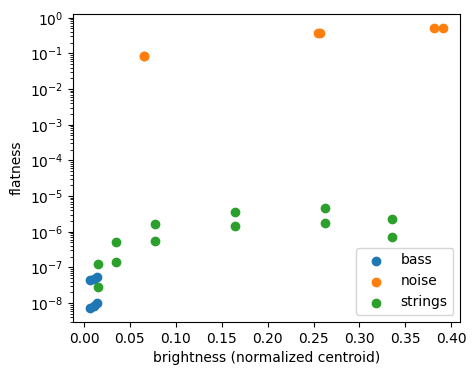

In [3]:
labels = dataset.item_labels("instrument")
values = collections.defaultdict(list)
for idx in range(len(dataset)):
    out = dataset[idx]
    values[labels[idx]].append((out["brightness"].mean().item(), out["flatness"].mean().item()))

fig, ax = plt.subplots(figsize=(5, 4))
for name, v in values.items():
    v = np.array(v); ax.scatter(v[:, 0], v[:, 1], label=name)
ax.set_xlabel("brightness (normalized centroid)"); ax.set_ylabel("flatness"); ax.set_yscale("log"); ax.legend(); plt.show()

## Querying from metadata

`query_from_features` draws items with given metadata values :

In [5]:
query = dataset.query_from_features(3, instrument="noise")
print({k: len(v) for k, v in query.items()})                       # {(value,): [items]}
query = dataset.query_from_features(2, instrument="strings", register="high")
print({k: [tuple(item["waveform"].shape) for item in v] for k, v in query.items()})

{('noise',): 3}
{('strings', 'high'): [(1, 16000), (1, 16000)]}


## Batch features

Features computed in workers are computed item by item. With `batch_features`, they are computed on whole batches
in the main process, on `device` (e.g. `"cuda"`) : useful for heavy features like neural embeddings.

In [6]:
loader = dataset.get_loader(batch_size=8, batch_features=["mel", "loudness"], device="cpu")
batch = next(iter(loader))
print({k: tuple(v.shape) for k, v in batch.items()})

{'waveform': (8, 1, 16000), 'brightness': (8, 7), 'loudness': (8,), 'flatness': (8, 7), 'mel': (8, 1, 128, 81), 'index': (8,)}


## Balancing classes

The dataset is imbalanced : 6 strings files, 3 bass files and 3 noise files. `balance_by` samples metadata values
uniformly (`balance_power` between 0 and 1 softens balancing), and can combine several features :

In [7]:
registers = dataset.item_labels("register")
print("natural sampling         :", collections.Counter(labels[i] for i in dataset.get_sampler(seed=0, max_samples=2000)))
print("balance_by instrument    :", collections.Counter(labels[i] for i in dataset.get_sampler(balance_by="instrument", seed=0, max_samples=2000)))
print("balance_power=0.5        :", collections.Counter(labels[i] for i in dataset.get_sampler(balance_by="instrument", balance_power=0.5, seed=0, max_samples=2000)))
pairs = [(labels[i], registers[i]) for i in dataset.get_sampler(balance_by=["instrument", "register"], seed=0, max_samples=2000)]
print("instrument x register    :", collections.Counter(pairs))

natural sampling         : Counter({'strings': 1000, 'bass': 513, 'noise': 487})
balance_by instrument    : Counter({'noise': 688, 'bass': 674, 'strings': 638})
balance_power=0.5        : Counter({'strings': 813, 'bass': 602, 'noise': 585})
instrument x register    : Counter({('strings', 'high'): 420, ('noise', 'low'): 412, ('bass', 'low'): 408, ('noise', 'high'): 394, ('strings', 'low'): 366})


## Pre-processed datasets

`preprocess` compiles the dataset (audio, features and metadata) into an LMDB database : features are then read
instead of being computed. Pre-processed datasets have the same interface.

In [8]:
compiled = dataset.preprocess(root.parent / "compiled", force=True)
print(type(compiled).__name__, len(compiled), {k: tuple(v.shape) for k, v in compiled[0].items()})

Exception ignored in: <function BaseEventLoop.__del__ at 0x104554a60>
Traceback (most recent call last):
  File "/Users/domkirke/miniconda3/envs/acidsdataset/lib/python3.10/asyncio/base_events.py", line 687, in __del__
    if not self.is_closed():
  File "/Users/domkirke/miniconda3/envs/acidsdataset/lib/python3.10/asyncio/base_events.py", line 684, in is_closed
    return self._closed
AttributeError: '_UnixSelectorEventLoop' object has no attribute '_closed'
100%|██████████| 12/12 [00:01<00:00,  6.53it/s]


PreprocessedAudioDataset 48 {'waveform': (1, 16000), 'brightness': (7,), 'loudness': (), 'flatness': (7,), 'mel': (1, 128, 81), 'index': ()}
